# Wet chemistry

> Compare the soil properties of the Fukushima samples with those of OSSL in a PCA, to see whether the Fukushima soils fall within the range of OSSL soils

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from soilspecdata.all import load_ossl
from ossl_fuku_transfer.data import *
from ossl_fuku_transfer.inside import nn_ratio
from sklearn.neighbors import NearestNeighbors
from soilspecdl.all import get_splitter
from ossl_fuku_transfer.transfer import preprocessings, load_pretrained, predict, scores

/Users/franckalbinet/pro/dev/soilspec/ossl-fuku-transfer/.venv/lib/python3.13/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


`07_inside_transfer` found that Fukushima spectra sit outside OSSL in every layer of every model. This notebook asks the same question of the soils themselves, through the properties both datasets measured. If the Fukushima soils fall within OSSL in property space, the transfer gap more likely lies in the spectra, through the instrument or sample preparation, than in the soils.

Every code cell reads OSSL or the Fukushima data, and is marked `#| fukudata`.

## Shared properties

Seven properties are measured in both datasets: exchangeable K, Mg and Ca, CEC, total C, total N and pH in water. `fuku_shared_props` and `ossl_shared_props` from `00_data` give them in the same units, with clay, and say how the units were converted.

The soil properties come from the current selection of Fukushima samples, and from the OSSL samples with a MIR spectrum on the shared grid, as in the other notebooks:

In [ ]:
#| fukudata
om = load_ossl().mir(wmin=shared_wns[0], wmax=shared_wns[-1])
ossl, fuku = ossl_shared_props(om), fuku_shared_props()
props = shared_props
pd.DataFrame({'OSSL': ossl[props].notna().all(axis=1).sum(), 'OSSL Andisols': (ossl[props].notna().all(axis=1) & ossl.andisol).sum(),
              'Fukushima': fuku[props].notna().all(axis=1).sum(), 'Fukushima Andosols': (fuku[props].notna().all(axis=1) & (fuku.soil == 'Andosols')).sum()}, index=['complete samples'])

,OSSL,OSSL Andisols,Fukushima,Fukushima Andosols
complete samples,49626,1405,1385,213


The 5th, 50th and 95th percentiles of each property, with K as a share of CEC in %. Fukushima's are the first row of each group:

In [ ]:
#| fukudata
for d in (ossl, fuku): d['K/CEC %'] = 100 * d.K / d.CEC
groups = {'Fukushima': fuku, 'Fukushima Andosols': fuku[fuku.soil == 'Andosols'], 'OSSL': ossl, 'OSSL Andisols': ossl[ossl.andisol]}
q = pd.concat({g: d[props + ['clay', 'K/CEC %']].quantile([0.05, 0.5, 0.95]) for g, d in groups.items()})
q.round(2)

K     Mg     Ca  ...    pH   clay  K/CEC %
Fukushima          0.05  0.22   0.38   2.35  ...  5.00   7.22     1.19
                   0.50  0.64   1.63   6.95  ...  5.60  19.40     3.59
                   0.95  1.63   5.36  15.86  ...  6.50  35.80     8.10
Fukushima Andosols 0.05  0.22   0.38   2.22  ...  5.10   6.50     0.95
                   0.50  0.60   1.12   6.88  ...  5.70  20.15     3.06
                   0.95  1.40   3.22  13.44  ...  6.20  38.30     7.33
OSSL               0.05  0.02   0.02   0.05  ...  4.40   2.13     0.05
                   0.50  0.35   2.72  11.35  ...  6.23  21.85     2.47
                   0.95  2.24  18.63  69.25  ...  8.44  59.05    11.92
OSSL Andisols      0.05  0.05   0.00   0.02  ...  4.69   1.48     0.28
                   0.50  0.37   0.80   3.59  ...  5.90   7.30     2.44
                   0.95  2.27   6.96  43.37  ...  6.95  36.02     8.74

[12 rows x 9 columns]

## PCA

The PCA is fitted on the OSSL samples with all seven properties, after `log1p` of all but pH and standardisation on OSSL. The Fukushima samples are projected onto it:

In [ ]:
#| fukudata
Fo, Ff = prop_features(ossl), prop_features(fuku)
pca = make_pipeline(StandardScaler(), PCA(random_state=0)).fit(Fo)
To, Tf = pca.transform(Fo), pca.transform(Ff)
ev = pca[-1].explained_variance_ratio_
pd.DataFrame(pca[-1].components_[:3].T, index=props, columns=[f'PC{i + 1} ({ev[i]:.0%})' for i in range(3)]).round(2)

,PC1 (50%),PC2 (26%),PC3 (10%)
K,0.36,0.08,0.81
Mg,0.42,0.26,0.13
Ca,0.41,0.38,-0.31
CEC,0.45,-0.14,0.07
C,0.40,-0.38,-0.30
N,0.37,-0.46,-0.23
pH,0.15,0.64,-0.30


The OSSL samples as a density in grey, OSSL Andisols in orange, and the Fukushima samples in blue, with Fukushima Andosols in red:

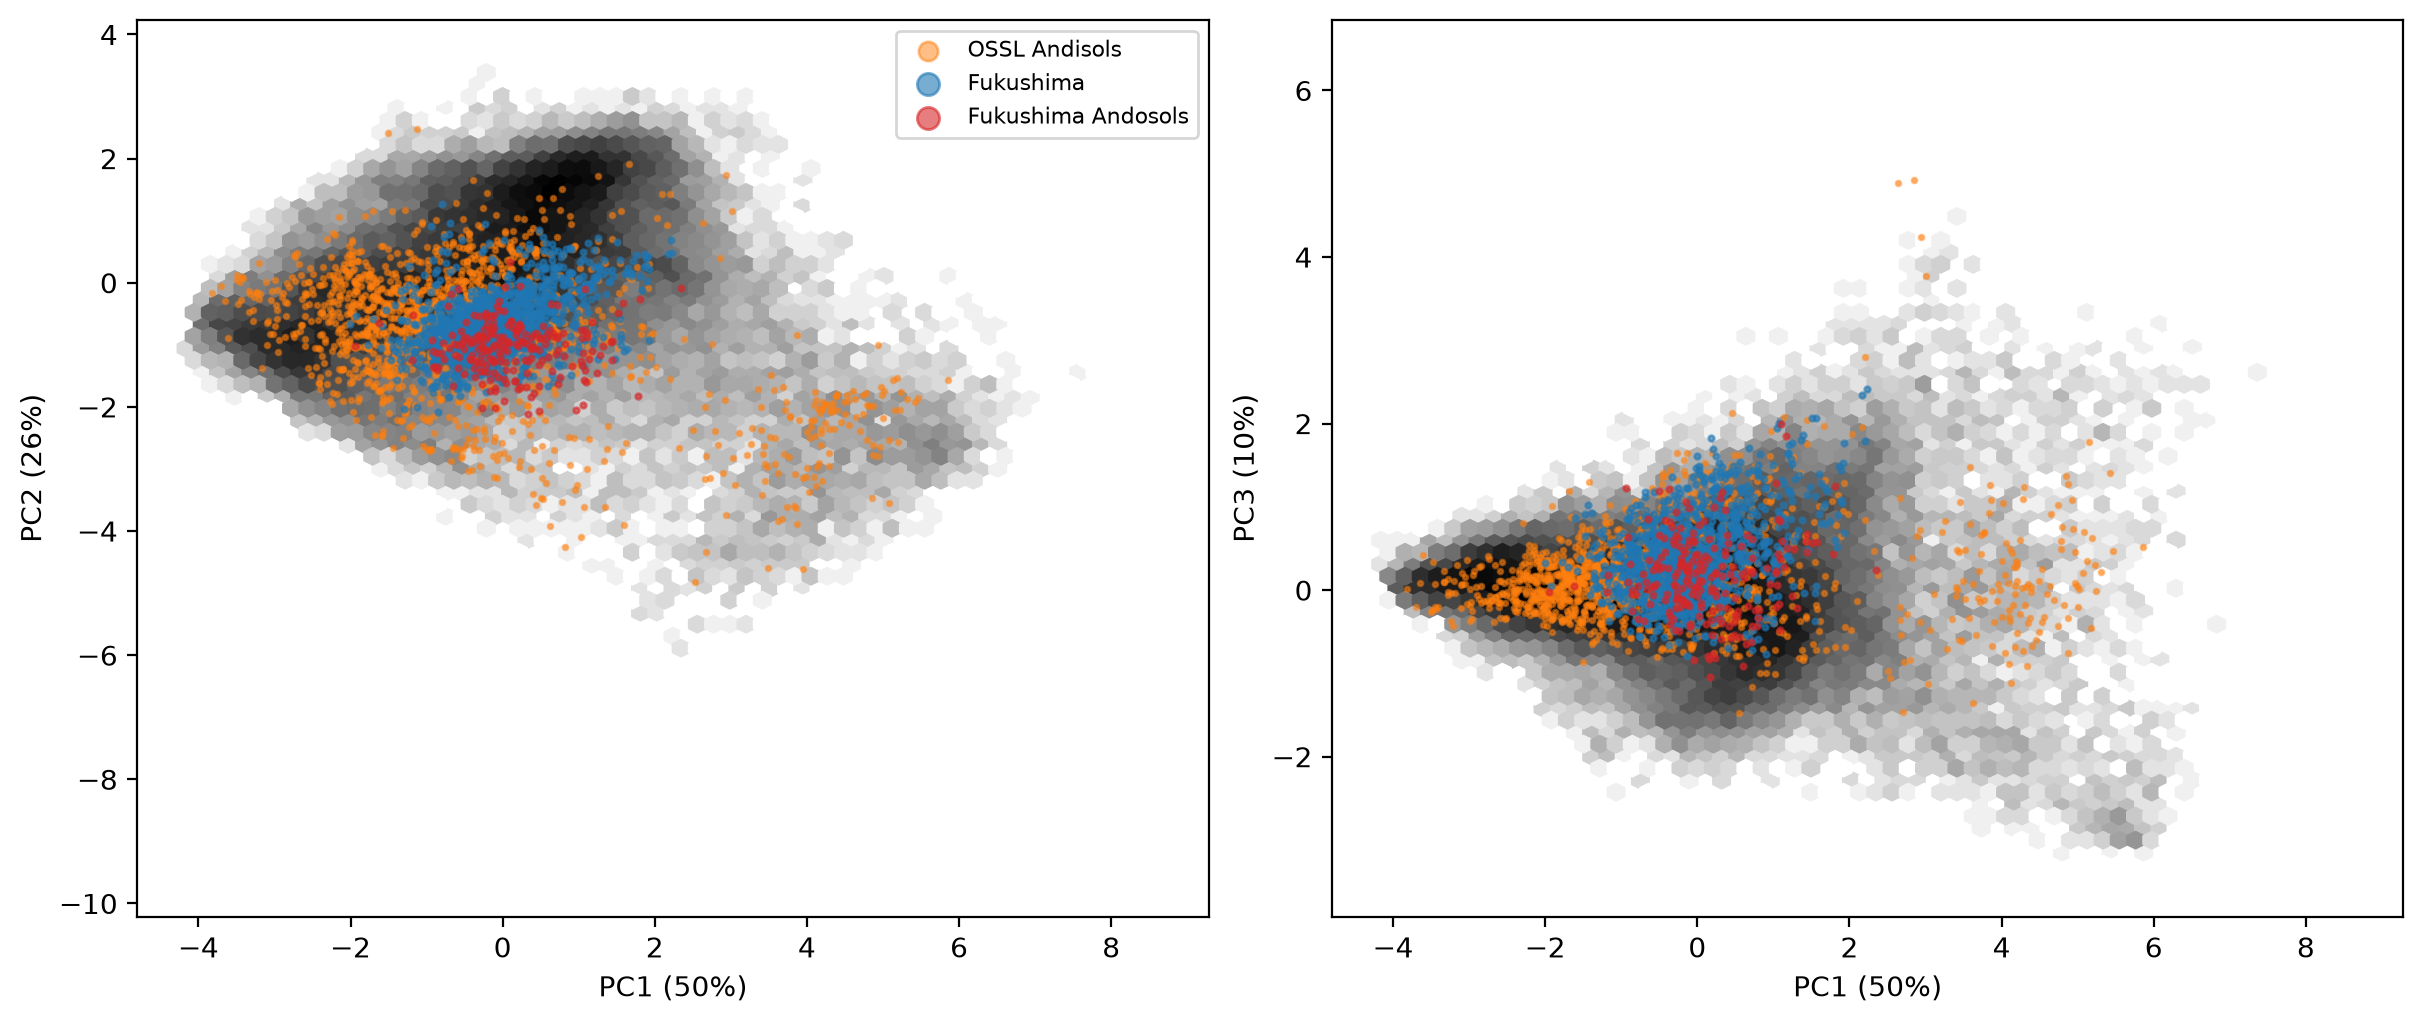

In [ ]:
#| fukudata
and_o = ossl.loc[Fo.index, 'andisol'].to_numpy()
and_f = (fuku.loc[Ff.index, 'soil'] == 'Andosols').to_numpy()
fig, axs = plt.subplots(1, 2, figsize=(12, 5), layout='constrained')
for ax, (i, j) in zip(axs, [(0, 1), (0, 2)]):
    ax.hexbin(To[:, i], To[:, j], gridsize=60, bins='log', cmap='Greys', mincnt=1)
    ax.scatter(To[and_o, i], To[and_o, j], s=3, c='tab:orange', alpha=0.5, label='OSSL Andisols')
    ax.scatter(Tf[~and_f, i], Tf[~and_f, j], s=4, c='tab:blue', alpha=0.6, label='Fukushima')
    ax.scatter(Tf[and_f, i], Tf[and_f, j], s=4, c='tab:red', alpha=0.6, label='Fukushima Andosols')
    ax.set_xlabel(f'PC{i + 1} ({ev[i]:.0%})'); ax.set_ylabel(f'PC{j + 1} ({ev[j]:.0%})')
axs[0].legend(markerscale=4, fontsize=8);

## Coverage

Two measures of how well OSSL covers the Fukushima soils in property space:

- the share of samples beyond OSSL's 99th percentile of Hotelling's T² over all seven components, which with seven properties is the squared Mahalanobis distance from the OSSL mean;
- `nn_ratio` from `07_inside_transfer`: the median distance to the nearest of 5,000 OSSL reference samples, relative to OSSL's own nearest-neighbour distance. As in `07`, OSSL samples outside the reference set, as many as there are Fukushima samples, are the control. The spectra gave a ratio of 2.5 at the input.

Both on all samples, and on OSSL Andisols and Fukushima Andosols alone:

In [ ]:
#| fukudata
t2 = lambda T: (T**2 / pca[-1].explained_variance_).sum(1)
lim = np.quantile(t2(To), 0.99)
r = np.random.default_rng(0)
perm = r.permutation(len(Fo))
ref, held = perm[:5000], perm[5000:5000 + len(Ff)]
Zo, Zf = pca[0].transform(Fo), pca[0].transform(Ff)
cov = {'OSSL held out': {'n': len(held), 'beyond T² 99%': (t2(To[held]) > lim).mean(), 'nn_ratio': nn_ratio(Zo[ref], Zo[held], n_pca=7)},
       'Fukushima': {'n': len(Ff), 'beyond T² 99%': (t2(Tf) > lim).mean(), 'nn_ratio': nn_ratio(Zo[ref], Zf, n_pca=7)},
       'Fukushima Andosols': {'n': int(and_f.sum()), 'beyond T² 99%': (t2(Tf[and_f]) > lim).mean(), 'nn_ratio': nn_ratio(Zo[ref], Zf[and_f], n_pca=7)},
       'OSSL Andisols': {'n': int(and_o.sum()), 'beyond T² 99%': (t2(To[and_o]) > lim).mean(), 'nn_ratio': nn_ratio(Zo[ref], Zo[and_o], n_pca=7)}}
pd.DataFrame(cov).T.round(3)

,n,beyond T² 99%,nn_ratio
OSSL held out,1385.0,0.014,0.987
Fukushima,1385.0,0.000,1.127
Fukushima Andosols,213.0,0.000,1.331
OSSL Andisols,1405.0,0.004,1.093


The same PCA and coverage with clay added as an eighth property, on the samples that have it. Clay is below 2 µm in both datasets. Fukushima's silt and sand follow other size limits than OSSL's, so they are left out:

In [ ]:
#| fukudata
cols8 = props + ['clay']
Fo8, Ff8 = prop_features(ossl, cols8), prop_features(fuku, cols8)
pca8 = make_pipeline(StandardScaler(), PCA(random_state=0)).fit(Fo8)
To8, Tf8 = pca8.transform(Fo8), pca8.transform(Ff8)
t2_8 = lambda T: (T**2 / pca8[-1].explained_variance_).sum(1)
lim8 = np.quantile(t2_8(To8), 0.99)
perm8 = r.permutation(len(Fo8))
ref8, held8 = perm8[:5000], perm8[5000:5000 + len(Ff8)]
Zo8, Zf8 = pca8[0].transform(Fo8), pca8[0].transform(Ff8)
pd.DataFrame({'OSSL held out': {'n': len(held8), 'beyond T² 99%': (t2_8(To8[held8]) > lim8).mean(), 'nn_ratio': nn_ratio(Zo8[ref8], Zo8[held8], n_pca=8)},
              'Fukushima': {'n': len(Ff8), 'beyond T² 99%': (t2_8(Tf8) > lim8).mean(), 'nn_ratio': nn_ratio(Zo8[ref8], Zf8, n_pca=8)}}).T.round(3)

,n,beyond T² 99%,nn_ratio
OSSL held out,972.0,0.013,0.971
Fukushima,972.0,0.000,1.115


## Soil analogues

This section separates the soils from the spectra. Each Fukushima soil is matched to its nearest OSSL sample in the standardised space of the seven properties, its analogue. The analogues come only from the validation samples of each pretrained model, which the model never trained on. Kex is one of the matching properties, so the analogues span about the same Kex range as the Fukushima soils.

The pretrained OSSL model then predicts each target, without fine-tuning, from two sets of spectra: the analogues' OSSL spectra and the Fukushima spectra. Good predictions on the analogues and poor ones on Fukushima would place the problem in the Fukushima spectra. Poor predictions on both would place it in these soil conditions.

The match quality first: the distance from each Fukushima soil to its analogue, relative to the median nearest-neighbour distance among the OSSL validation samples, the number of distinct analogues, and the correlation between each Fukushima soil's property and its analogue's:

In [ ]:
#| fukudata
pipe = preprocessings()['snv_d1']
fk = load_fuku()
fpos = pd.Series(np.arange(len(fk.sample_ids)), index=fk.sample_ids)
Zo_df = pd.DataFrame(pca[0].transform(Fo), index=Fo.index)
Zf_df = pd.DataFrame(pca[0].transform(Ff), index=Ff.index)
Xf_d = pipe.fit_transform(fk.spectra[fpos[Zf_df.index].to_numpy()])
targets = {'Kex': ('k.ext_usda.a725_cmolc.kg', 'K', 'ossl_kex_snv_d1'), 'CEC': ('cec_usda.a723_cmolc.kg', 'CEC', 'ossl_cec_snv_d1')}
match, preds = {}, {}
for t, (col, prop, fname) in targets.items():
    Xo_t, yo_t, ido_t = om.xy(col)
    yo_t = yo_t.ravel()
    va = get_splitter(0.9, 0.1, seed=42)(Xo_t, yo_t)[1]
    vid = np.intersect1d(ido_t[va], Zo_df.index)
    nn = NearestNeighbors(n_neighbors=2).fit(Zo_df.loc[vid])
    d, j = nn.kneighbors(Zf_df, 1)
    an = vid[j[:, 0]]
    base = np.median(nn.kneighbors(Zo_df.loc[vid])[0][:, 1])
    pos = pd.Series(np.arange(len(ido_t)), index=ido_t)
    model = load_pretrained(fname)
    yv = np.log1p(yo_t[pos[vid].to_numpy()])
    yf_t = np.log1p(fuku.loc[Zf_df.index, prop].to_numpy())
    lo, hi = yf_t.min(), yf_t.max()
    pv = predict(model, pipe.transform(Xo_t[pos[vid].to_numpy()]))
    preds[t] = {'OSSL validation': (yv, pv), "OSSL validation in Fukushima's range": (yv[(yv >= lo) & (yv <= hi)], pv[(yv >= lo) & (yv <= hi)]),
                'OSSL analogues': (np.log1p(yo_t[pos[an].to_numpy()]), predict(model, pipe.transform(Xo_t[pos[an].to_numpy()]))),
                'Fukushima': (yf_t, predict(model, Xf_d))}
    match[t] = {'validation samples': len(vid), 'distinct analogues': len(np.unique(an)), 'median distance ratio': np.median(d[:, 0]) / base,
                'r, Fukushima and analogue property': np.corrcoef(yf_t, np.log1p(yo_t[pos[an].to_numpy()]))[0, 1]}
pd.DataFrame(match).round(3)

,Kex,CEC
validation samples,4963.000,4965.000
distinct analogues,424.000,453.000
median distance ratio,1.100,1.108
"r, Fukushima and analogue property",0.962,0.869


The scores of each pretrained model, without fine-tuning, on each set of spectra: R² and correlation `r` of `log1p` of the property, and the RMSE and bias of the property in cmolc/kg:

In [ ]:
#| fukudata
pd.DataFrame({(t, k): {'n': len(y), **scores(y, p)} for t, d in preds.items() for k, (y, p) in d.items()}).T.round(3)

n     R²      r   RMSE   bias
Kex OSSL validation                       4963.0  0.807  0.899  0.523 -0.020
    OSSL validation in Fukushima's range  4457.0  0.753  0.871  0.359 -0.009
    OSSL analogues                        1385.0  0.596  0.786  0.276 -0.046
    Fukushima                             1385.0 -0.764  0.152  0.584  0.300
CEC OSSL validation                       4965.0  0.968  0.984  5.691 -0.620
    OSSL validation in Fukushima's range  3577.0  0.894  0.949  3.294 -0.371
    OSSL analogues                        1385.0  0.881  0.942  1.783 -0.141
    Fukushima                             1385.0 -0.671  0.625  6.625 -3.213

Observed against predicted Kex on the analogues and on Fukushima:

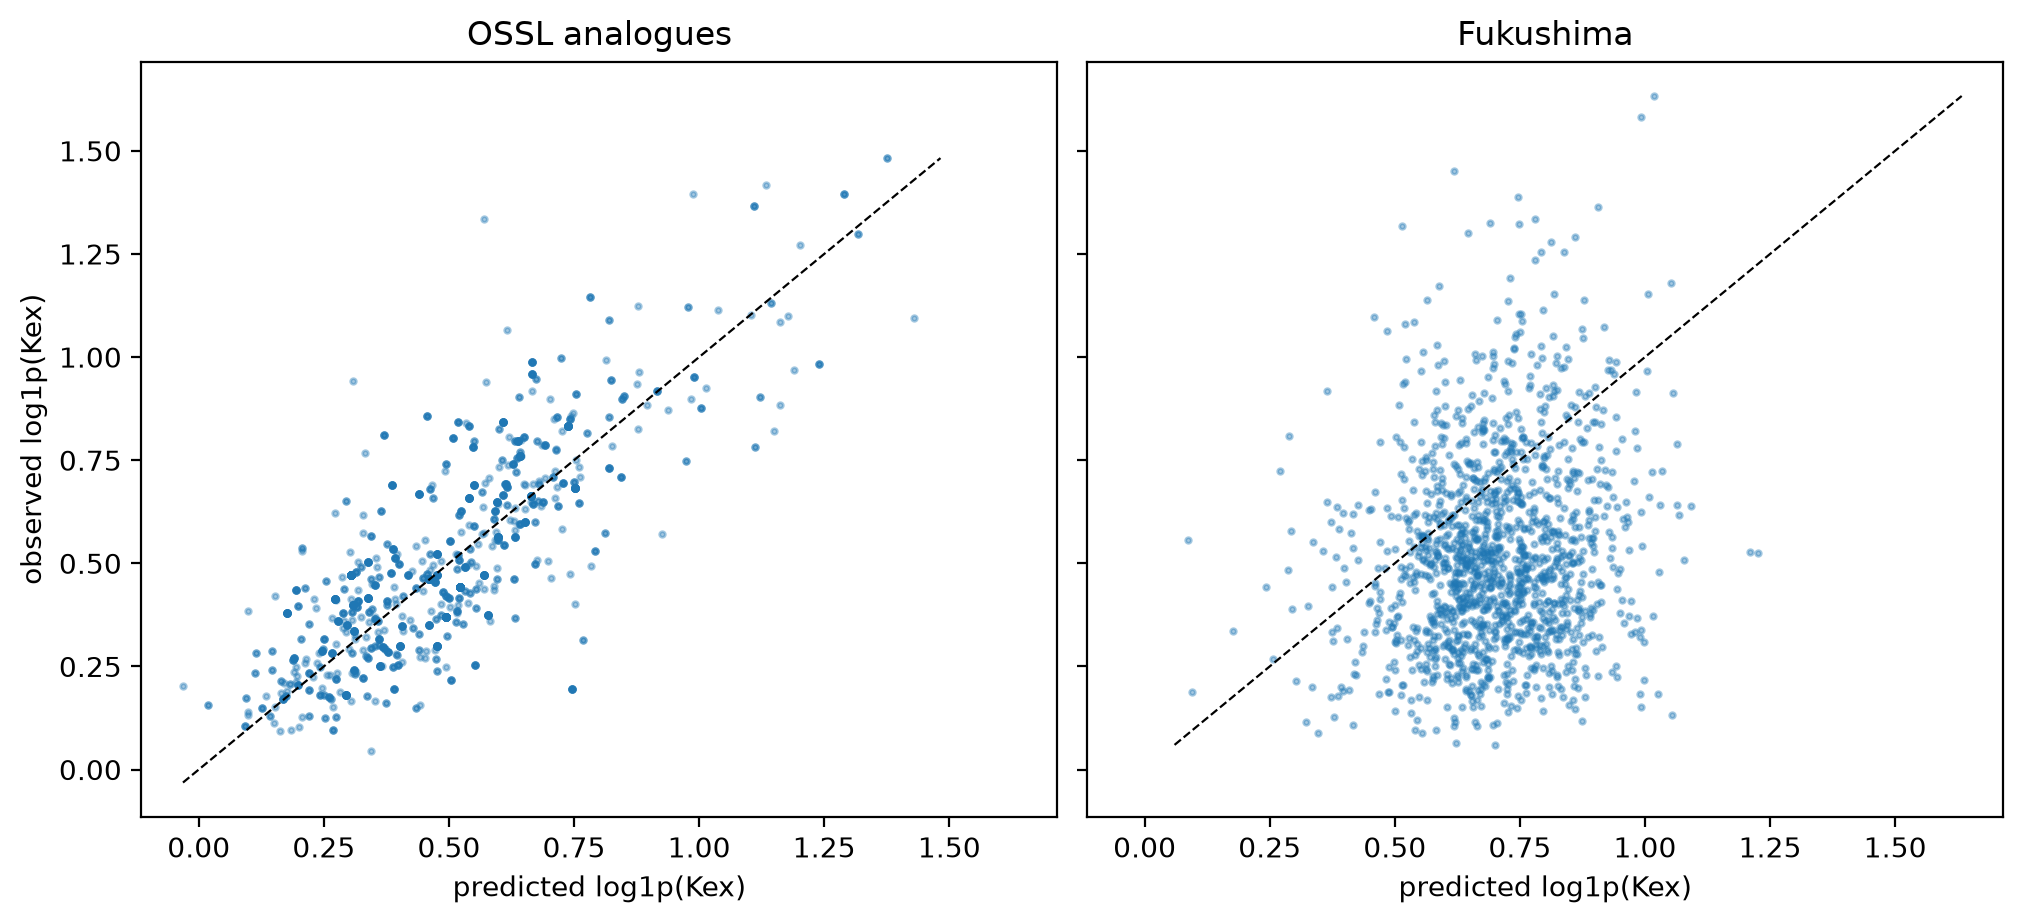

In [ ]:
#| fukudata
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True, layout='constrained')
for ax, k in zip(axs, ('OSSL analogues', 'Fukushima')):
    y, p = preds['Kex'][k]
    ax.scatter(p, y, s=4, alpha=0.4)
    lims = [min(y.min(), p.min()), max(y.max(), p.max())]
    ax.plot(lims, lims, 'k--', lw=0.8)
    ax.set_title(k); ax.set_xlabel('predicted log1p(Kex)')
axs[0].set_ylabel('observed log1p(Kex)');

## Findings

In property space, OSSL covers the Fukushima soils. No Fukushima sample is beyond OSSL's 99th percentile of Hotelling's T², against 1.4% of held-out OSSL samples. The median distance from a Fukushima sample to its nearest OSSL sample is 1.13 times OSSL's own nearest-neighbour distance, against 0.99 for held-out OSSL samples. With clay as an eighth property, on 972 Fukushima samples, the ratio is the same, 1.13. On the spectra, the same ratio was 2.5 (`07_inside_transfer`). Each ratio compares with its own control, since the two spaces have different numbers of dimensions. Relative to those controls, the Fukushima soils are close to OSSL soils in their properties and far from them in their spectra.

The Fukushima Andosols sit a little further out (ratio 1.33), but within the T² limit, as do the OSSL Andisols (1.09). They differ from the OSSL Andisols in these properties: at the median, more exchangeable Ca (6.9 against 3.6 cmolc/kg), C (3.3 against 1.8%) and clay (20 against 7%).

The Fukushima soils span a narrower range than OSSL for every property. Their pH runs from 5.0 to 6.5 between the 5th and 95th percentiles, against 4.4 to 8.4 in OSSL.

Exchangeable K is higher in Fukushima than in OSSL, both on its own and as a share of CEC. At the median, Kex is 0.64 against 0.35 cmolc/kg, and K is 3.6% of CEC against 2.5%. For the Andosols and Andisols, K is 3.1% of CEC against 2.4%. This is consistent with potassium fertilisation after 2011, but these data don't show the cause.

The OSSL Kex model predicts the Fukushima soils' OSSL analogues well and the Fukushima spectra poorly. On the analogues it gives R² 0.60 (r 0.79). On the Fukushima spectra of the soils they match, it gives R² −0.76 (r 0.15). The analogues are close matches: each lies at 1.10 times the median nearest-neighbour distance among OSSL validation samples, and their Kex correlates with the Fukushima soils' Kex at r 0.96. The CEC model shows the same pattern: R² 0.88 (r 0.94) on the analogues, against −0.67 (r 0.63) on Fukushima.

The 1,385 matches use 424 distinct Kex analogues and 453 distinct CEC analogues, since one OSSL sample can be the nearest to several Fukushima soils. The analogue scores count each OSSL sample as often as it is matched.

OSSL holds soils with properties like the Fukushima soils. From their OSSL spectra, the model predicts Kex less well than for OSSL validation samples overall (R² 0.81) or within Fukushima's Kex range, from its minimum to its maximum (0.75), but far better than from the Fukushima spectra. These seven properties don't describe mineralogy, such as the micas and short-range-order minerals that matter for K and Cs. Within what they measure, the zero-shot failure comes from the Fukushima spectra, through the instrument or sample preparation, and not from the soils.